# Simulation

In [1]:
import numpy as np
from wasabi.data_simulation import make_ground_truth_params
from wasabi.data_simulation import simulate_trial

In [2]:
K = 4
N = 128
spectral_radius = 0.9
sigma2_Q = 0.2
sigma2_C = 0.05
w = 3.0
b_input = -0.5
B_SCALE = 5.0  # roughly the std of B_true; keeps B_init at unit scale

rng = np.random.default_rng(1)
params_GT = make_ground_truth_params(K, N, spectral_radius, sigma2_Q, sigma2_C, w, b_input, B_scale=B_SCALE, seed=0)

print("Ground-truth parameters:")
for key, value in params_GT.items():
    print(f"  {key}: {value.shape if hasattr(value, 'shape') else type(value).__name__}")

Ground-truth parameters:
  A: (4, 4)
  B: (4, 128)
  b: float
  C: (128, 4)
  d: (128,)
  Q: (4, 4)
  mu0: (4,)
  Sigma0: (4, 4)
  V: (128, 128)


In [3]:
from wasabi.data_simulation import blank_stim_artifact

# Simulation params
T = 60          # within-trial timesteps
t_stim = 25      # stim delivered at this timestep
n_stim_ch = 8    # number of channels stimulated per trial
n_conditions = 10
n_repetitions = 10
n_trials = n_conditions * n_repetitions

# Stim params
BETA_STIM = 5.0    # sharp threshold, this is the science
BETA_EMIT = 1.0    # soft link, this is just the observation model
BIN_SIZE = 20.0
STIM_DUR = 100.0
ms_before, tail_ms = 0.0, 0.0
n_stim_bins = int(round(STIM_DUR / BIN_SIZE))
n_blank = int(np.ceil((ms_before + STIM_DUR + tail_ms) / BIN_SIZE))

# Pad extra time for simulation
pad_T = 40
T_total = T + pad_T
t_stim_padded = t_stim + pad_T

# Preallocate at the padded length
S = np.zeros((n_trials, T_total, N))
X = np.zeros((n_trials, T_total, K))
Y = np.zeros((n_trials, T_total, N), dtype=int)
cond_id = np.repeat(np.arange(n_conditions), n_repetitions)
    
# Simulate with padded time, then trim
for cond in range(n_conditions):
    start_idx = rng.integers(0, N - n_stim_ch + 1)
    stim_channels = np.arange(start_idx, start_idx + n_stim_ch)
    for repetition in range(n_repetitions):
        i = cond * n_repetitions + repetition
        x, y, s = simulate_trial(params_GT, T_total, stim_channels, t_stim_padded, n_stim_bins, rng, softplus_beta_emit=BETA_EMIT, softplus_beta_stim=BETA_STIM)
        X[i], Y[i], S[i] = x, y, s
        cond_id[i] = cond

# Trim off the burn-in period
X = X[:, pad_T:, :]
Y = Y[:, pad_T:, :]
S = S[:, pad_T:, :]

Y_obs = blank_stim_artifact(Y, t_stim, n_blank)

X_spread = np.zeros((n_trials, T_total, K))
Y_spread = np.zeros((n_trials, T_total, N), dtype=int)
S_spread = np.zeros((n_trials, T_total, N))
cond_id_spread = np.zeros(n_trials, dtype=int)

for cond in range(n_conditions):
    stim_channels_spread = rng.choice(N, size=n_stim_ch, replace=False)
    for repetition in range(n_repetitions):
        i = cond * n_repetitions + repetition
        x_spread, y_spread, s_spread = simulate_trial(
            params_GT, T_total, stim_channels_spread, t_stim_padded, n_stim_bins, rng, softplus_beta_emit=BETA_EMIT, softplus_beta_stim=BETA_STIM)
        X_spread[i], Y_spread[i], S_spread[i] = x_spread, y_spread, s_spread
        cond_id_spread[i] = cond

X_spread = X_spread[:, pad_T:, :]
Y_spread = Y_spread[:, pad_T:, :]
S_spread = S_spread[:, pad_T:, :]
    
print("X (latents):", X.shape) # n_trials x time x latent_dim
print("Y (spikes):", Y.shape) # n_trials x time x obs_dim
print("S (stim):", S.shape) # n_trials x time x obs_dim

t_ms = (np.arange(X.shape[1]) - t_stim) * BIN_SIZE
t_edges_ms = np.r_[t_ms - BIN_SIZE / 2, t_ms[-1] + BIN_SIZE / 2]
blank_ms = (0, STIM_DUR)

stim_t_ms = 0.0

X (latents): (100, 60, 4)
Y (spikes): (100, 60, 128)
S (stim): (100, 60, 128)


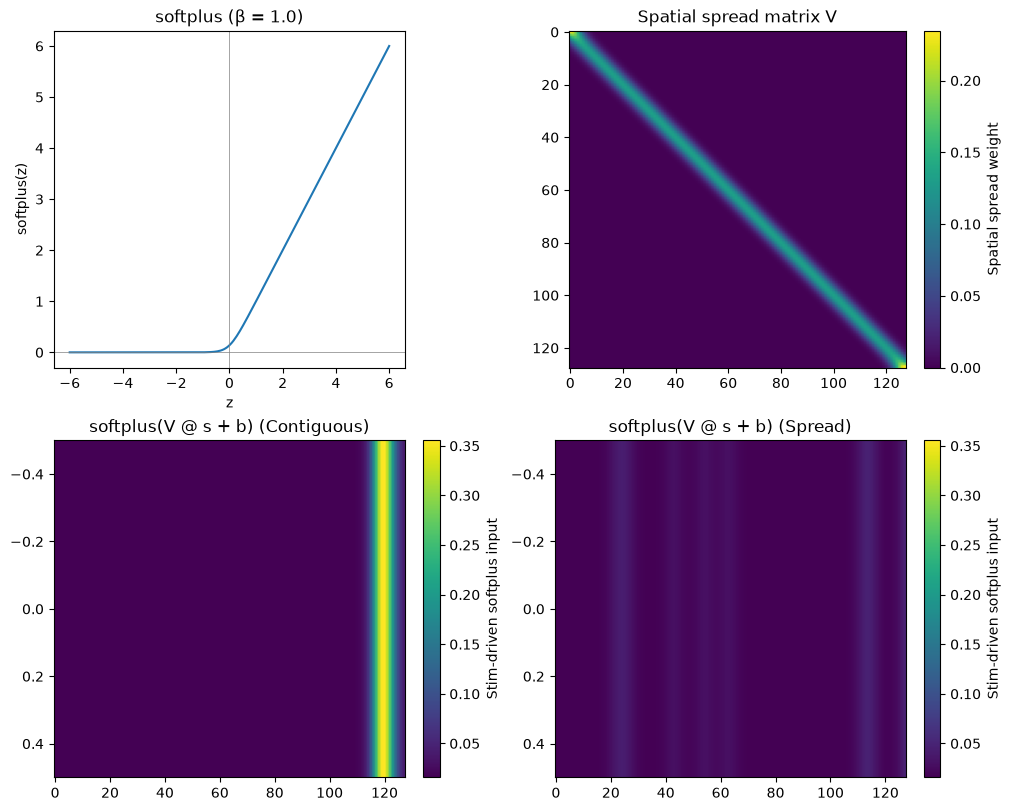

In [4]:
import matplotlib.pyplot as plt
from wasabi.utils import softplus_np

s_temp = np.zeros(N)
s_temp_spread = np.zeros(N)
s_temp[stim_channels] = 1.0
s_temp_spread[stim_channels_spread] = 1.0

fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)

# Top left: softplus
z_range = np.linspace(-6, 6, 200)
axes[0, 0].plot(z_range, softplus_np(z_range))
axes[0, 0].axhline(0, color="grey", linewidth=0.5)
axes[0, 0].axvline(0, color="grey", linewidth=0.5)
axes[0, 0].set_title(f"softplus (β = {BETA_EMIT})")
axes[0, 0].set_xlabel("z")
axes[0, 0].set_ylabel("softplus(z)")

# Top right: V matrix
im0 = axes[0, 1].imshow(params_GT['V'], cmap='viridis')
axes[0, 1].set_title("Spatial spread matrix V")
fig.colorbar(im0, ax=axes[0, 1], label='Spatial spread weight')

# Bottom left
stim_effect = softplus_np(params_GT['V'] @ s_temp + params_GT['b'], beta=BETA_STIM)
stim_effect_spread = softplus_np(params_GT['V'] @ s_temp_spread + params_GT['b'], beta=BETA_STIM)

vmin, vmax = stim_effect.min(), stim_effect.max()  # Get colorbar from first

im1 = axes[1, 0].imshow(stim_effect[None, :], cmap='viridis', aspect='auto', vmin=vmin, vmax=vmax)
axes[1, 0].set_title(f"softplus(V @ s + b) (Contiguous)")
fig.colorbar(im1, ax=axes[1, 0], label='Stim-driven softplus input')

# Bottomr right is spread
im2 = axes[1, 1].imshow(stim_effect_spread[None, :], cmap='viridis', aspect='auto', vmin=vmin, vmax=vmax)
axes[1, 1].set_title(f"softplus(V @ s + b) (Spread)")
fig.colorbar(im2, ax=axes[1, 1], label='Stim-driven softplus input')

plt.show()

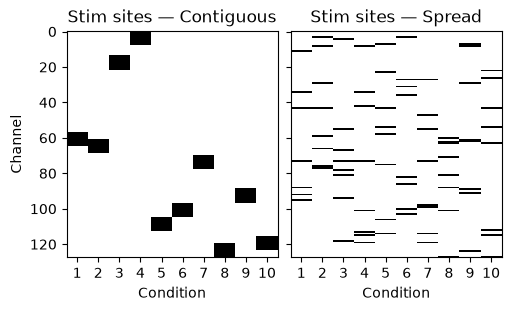

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(5, 3), constrained_layout=True, sharey=True)

for ax, (stim, trial_conditions, name) in zip(
        axes, [(S, cond_id, "Contiguous"), (S_spread, cond_id_spread, "Spread")]):
    conditions = np.unique(trial_conditions)
    stim_patterns = np.stack([
        stim[trial_conditions == condition, t_stim, :].mean(axis=0)
        for condition in conditions
    ])
    ax.imshow(stim_patterns.T, aspect="auto", cmap="Greys",
              interpolation="nearest", vmin=0, vmax=1)
    ax.set_xticks(np.arange(len(conditions)))
    ax.set_xticklabels(conditions + 1)
    ax.set_title(f"Stim sites — {name}")
    ax.set_xlabel("Condition")

axes[0].set_ylabel("Channel")
plt.show()

In [6]:
cond = 0
stat = np.nanmean
colors = plt.cm.tab10(np.arange(K))

psth_c = stat(Y[cond_id == cond], axis=0)
psth_s = stat(Y_spread[cond_id_spread == cond], axis=0)

vmin = min(psth_c.min(), psth_s.min())
vmax = max(psth_c.max(), psth_s.max())

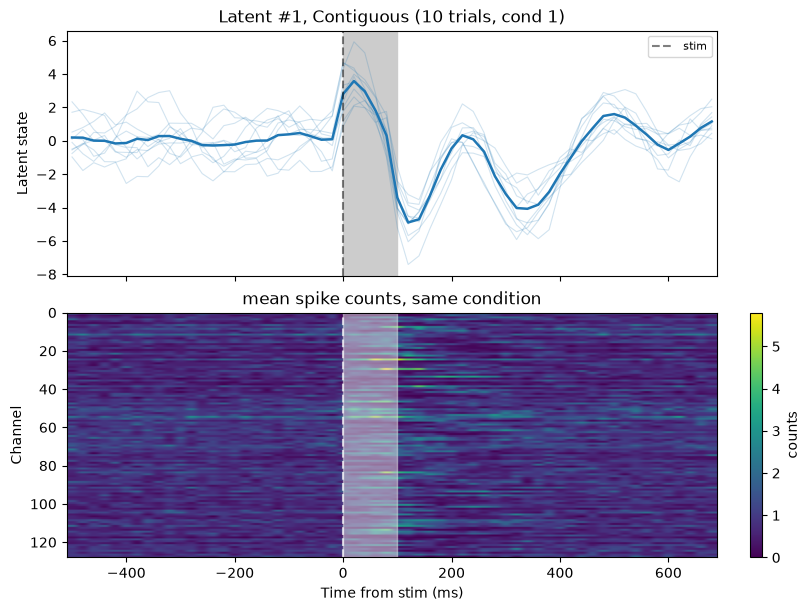

In [7]:
name = "Contiguous"
Xd, Yd, trial_conditions = X, Y, cond_id
latent = 0

sel = trial_conditions == cond
Xsel, Ysel = Xd[sel], Yd[sel]

fig, axes = plt.subplots(2, 1, figsize=(8, 6), constrained_layout=True, sharex=True)

for trace in Xsel[:, :, latent]:
    axes[0].plot(t_ms, trace, color=colors[latent], alpha=0.2, linewidth=0.8)

axes[0].plot(t_ms, Xsel[:, :, latent].mean(axis=0), color=colors[latent], linewidth=1.8)
axes[0].axvline(stim_t_ms, color="k", linestyle="--", alpha=0.5, label="stim")
axes[0].axvspan(*blank_ms, color="0.8", zorder=0)
axes[0].set_title(f"Latent #1, {name} ({sel.sum()} trials, cond {cond+1})")
axes[0].set_ylabel("Latent state")
axes[0].legend(fontsize=8)

extent = [t_edges_ms[0], t_edges_ms[-1], Ysel.shape[2], 0]
im = axes[1].imshow(stat(Ysel, axis=0).T, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax, extent=extent)
axes[1].axvline(stim_t_ms, color="w", linestyle="--", alpha=0.7)
axes[1].axvspan(*blank_ms, color="0.9", alpha=0.5, zorder=1)
axes[1].set_title(f"{stat.__name__.replace('nan', '')} spike counts, same condition")
axes[1].set_xlabel("Time from stim (ms)")
axes[1].set_ylabel("Channel")
fig.colorbar(im, ax=axes[1], label="counts")
plt.show()

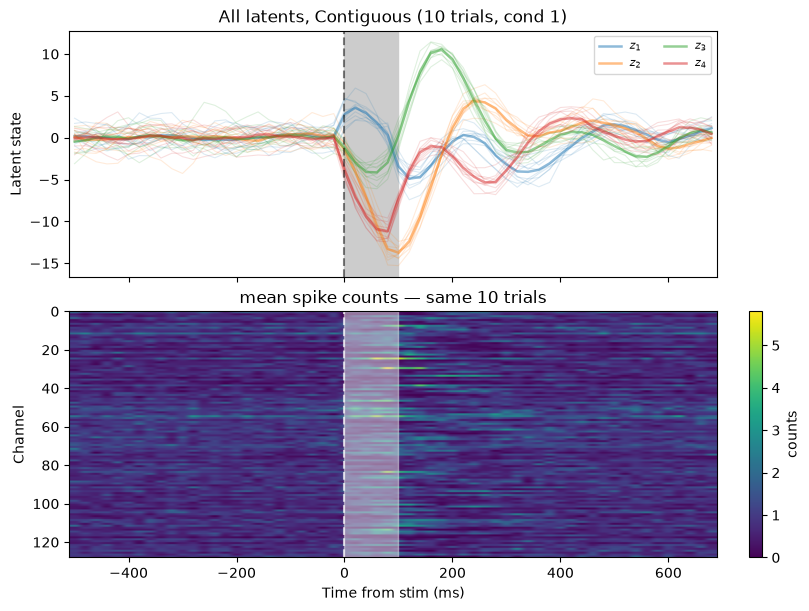

In [8]:
name = "Contiguous"
Xd, Yd, trial_conditions = X, Y, cond_id

sel = trial_conditions == cond
Xsel, Ysel = Xd[sel], Yd[sel]

fig, axes = plt.subplots(2, 1, figsize=(8, 6), constrained_layout=True, sharex=True)

for k in range(K):
    for trace in Xsel[:, :, k]:
        axes[0].plot(t_ms, trace, color=colors[k], alpha=0.15, linewidth=0.8)
    axes[0].plot(t_ms, Xsel[:, :, k].mean(axis=0), color=colors[k], linewidth=1.8, alpha=0.5, label=rf"$z_{{{k+1}}}$")

axes[0].axvline(stim_t_ms, color="k", linestyle="--", alpha=0.5)
axes[0].axvspan(*blank_ms, color="0.8", zorder=0)
axes[0].set_title(f"All latents, {name} ({sel.sum()} trials, cond {cond+1})")
axes[0].set_ylabel("Latent state")
axes[0].legend(fontsize=8, ncol=2)

extent = [t_edges_ms[0], t_edges_ms[-1], Ysel.shape[-1], 0]
im = axes[1].imshow(stat(Ysel, axis=0).T, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax, extent=extent)
axes[1].axvline(stim_t_ms, color="w", linestyle="--", alpha=0.7)
axes[1].axvspan(*blank_ms, color="0.9", alpha=0.5, zorder=1)
axes[1].set_title(f"{stat.__name__.replace('nan', '')} spike counts — same {sel.sum()} trials")
axes[1].set_xlabel("Time from stim (ms)")
axes[1].set_ylabel("Channel")
fig.colorbar(im, ax=axes[1], label="counts")
plt.show()

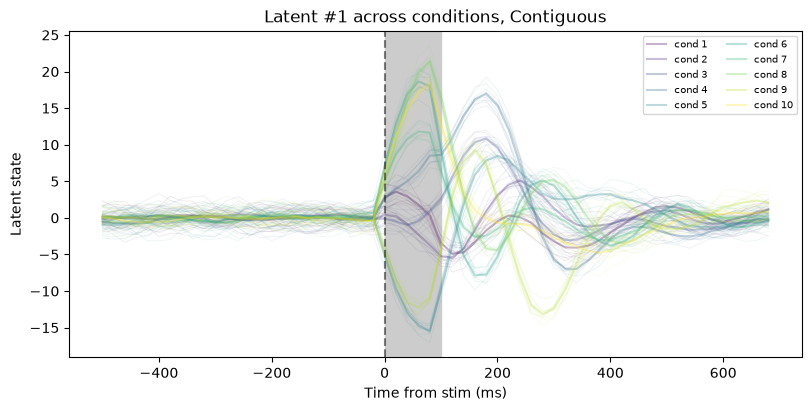

In [9]:
name = "Contiguous"
Xd, trial_conditions = X, cond_id
latent = 0
show_trials = True

conditions = np.unique(trial_conditions)
cmap = plt.cm.viridis(np.linspace(0, 1, len(conditions)))

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)

for j, condition in enumerate(conditions):
    traces = Xd[trial_conditions == condition, :, latent]
    if show_trials:
        for trace in traces:
            ax.plot(t_ms, trace, color=cmap[j], alpha=0.08, linewidth=0.7)
    ax.plot(t_ms, traces.mean(axis=0), color=cmap[j], linewidth=1.5, alpha=0.3, label=f"cond {condition+1}")

ax.axvspan(*blank_ms, color="0.8", zorder=0)
ax.axvline(stim_t_ms, color="k", linestyle="--", alpha=0.5)
ax.set_title(f"Latent #1 across conditions, {name}")
ax.set_xlabel("Time from stim (ms)")
ax.set_ylabel("Latent state")
ax.legend(fontsize=7, ncol=2)
plt.show()

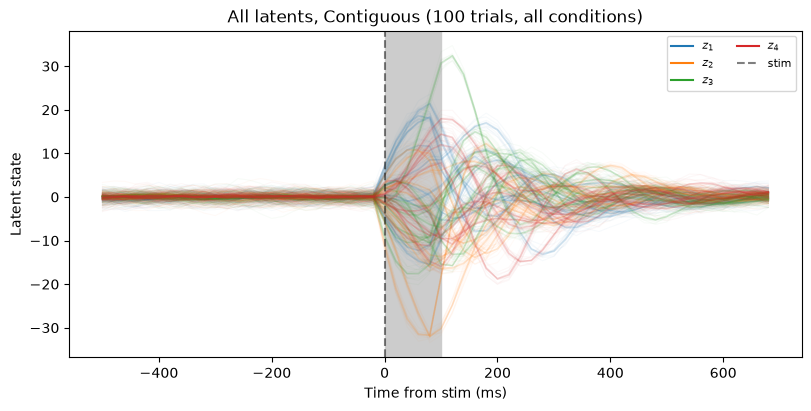

In [10]:
name = "Contiguous"
Xd, trial_conditions = X, cond_id
show_trials = True

conditions = np.unique(trial_conditions)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)

for k in range(K):
    if show_trials:
        for trace in Xd[:, :, k]:
            ax.plot(t_ms, trace, color=colors[k], alpha=0.03, linewidth=0.8)
    for condition in conditions:
        ax.plot(t_ms, Xd[trial_conditions == condition, :, k].mean(axis=0), color=colors[k], linewidth=1.2, alpha=0.2)
    ax.plot([], [], color=colors[k], label=rf"$z_{{{k+1}}}$")

ax.axvspan(*blank_ms, color="0.8", zorder=0)
ax.axvline(stim_t_ms, color="k", linestyle="--", alpha=0.5, label="stim")
ax.set_title(f"All latents, {name} ({Xd.shape[0]} trials, all conditions)")
ax.set_xlabel("Time from stim (ms)")
ax.set_ylabel("Latent state")
ax.legend(fontsize=8, ncol=2, loc="upper right")
plt.show()

# Recover parameters

In [11]:
import jax.numpy as jnp
import jax.random as jr
import optax
import matplotlib.pyplot as plt
from jax import value_and_grad, jit

In [12]:
key = jr.key(0)
key1, key2 = jr.split(key, 2)
state_dim = 4
num_trials, num_timesteps, observations_dim = Y.shape

In [14]:
from wasabi.plds_fit import loss_fn
from wasabi.utils import softplus_jnp, softplus_inv_np

# Poisson LDS
# Initialization
# Known V
V = jnp.asarray(params_GT["V"])

def to_model_inputs(S):
    # shift back one bin to fit DYNAMAX inputs
    S = jnp.asarray(S)
    return jnp.concatenate([S[:, 1:], jnp.zeros_like(S[:, :1])], axis=1)

inputs = to_model_inputs(S)

# Create blanking mask and 0 in place of nans for all_obs
KEEP = jnp.asarray(np.isfinite(Y_obs).all(axis=-1))   # (n_trials, T)
blank = ~np.asarray(KEEP).any(axis=0)                 # (T,) for plotting only

# Process noise assume known TODO
Q_dyn = 0.2 * jnp.eye(state_dim)

# Initialize with mean spike counts
mean_counts = np.nanmean(Y_obs, axis=(0, 1))
d_init = jnp.asarray(softplus_inv_np(np.maximum(mean_counts, 1e-3), beta=BETA_EMIT))

# Dynamics params
A_init = 0.9 * jnp.eye(state_dim)

# Observation params
C_init = 0.1 * jr.normal(key2, shape=(observations_dim, state_dim))
B_init = (0.01 / B_SCALE) * jr.normal(key1, (state_dim, observations_dim))
b_init = jnp.array(-0.2)

theta = (C_init, d_init, A_init, B_init, b_init)

# SGD
optimizer = optax.adam(5e-3) # 1e-3 or 1e-4
opt_state = optimizer.init(theta)

@jit
def step(theta, opt_state, observations, inputs):
    """
    Perform descent step using the CMGS negative log-likelihood as the loss function.
    Use Adam + autograd to compute gradients.

    Returns:
        Updated parameters
        New optimizer state
        Current loss
    """
    loss, grads = value_and_grad(loss_fn)(theta, observations, inputs, KEEP, Q_dyn, V, B_SCALE, BETA_STIM, BETA_EMIT)
    updates, new_opt_state = optimizer.update(grads, opt_state)
    return optax.apply_updates(theta, updates), new_opt_state, loss

losses = []
n_epochs = 500
for epoch in range(n_epochs):
    theta, opt_state, loss = step(theta, opt_state, Y_obs, inputs)
    losses.append(float(loss))
    if epoch % 25 == 0:
        print(f"epoch {epoch:4d}  neg-loglik = {loss:.2f}")

C_fit, d_fit, A_fit, B_fit, b_fit = theta

print("Recovered d range:", float(d_fit.min()), float(d_fit.max()))
print("Ground truth d range:", float(params_GT["d"].min()), float(params_GT["d"].max()))
print("Recovered threshold:", float(b_fit), " ground truth:", params_GT["b"])
print("|B_fit| max:", float(jnp.abs(B_SCALE * B_fit).max()),
      " |B_true| max:", float(np.abs(params_GT["B"]).max()))

epoch    0  neg-loglik = 865683.12
epoch   25  neg-loglik = 838762.38
epoch   50  neg-loglik = 816824.62
epoch   75  neg-loglik = 807370.38
epoch  100  neg-loglik = 806623.88
epoch  125  neg-loglik = 806468.19
epoch  150  neg-loglik = 806417.31
epoch  175  neg-loglik = 806389.50
epoch  200  neg-loglik = 806367.25
epoch  225  neg-loglik = 806348.38
epoch  250  neg-loglik = 806331.88
epoch  275  neg-loglik = 806318.50
epoch  300  neg-loglik = 806307.75
epoch  325  neg-loglik = 806299.38
epoch  350  neg-loglik = 806292.94
epoch  375  neg-loglik = 806288.56
epoch  400  neg-loglik = 806285.56
epoch  425  neg-loglik = 806283.62
epoch  450  neg-loglik = 806282.12
epoch  475  neg-loglik = 806281.62
Recovered d range: -1.4474096298217773 1.557796835899353
Ground truth d range: -1.498672695841814 1.5372502406970658
Recovered threshold: 0.09859702736139297  ground truth: -0.5
|B_fit| max: 2.106234073638916  |B_true| max: 19.497108650271695


In [15]:
from wasabi.utils import softplus_np

lam = softplus_np(X @ params_GT["C"].T + params_GT["d"], BETA_EMIT)
hz = 1000.0 / BIN_SIZE
print("baseline Hz       :", lam[:, :t_stim].mean() * hz)
print("peak Hz           :", lam.max() * hz)
print("min rate          :", lam.min())

baseline Hz       : 39.97336392949715
peak Hz           : 542.5303552510081
min rate          : 1.7081583465180177e-05


In [16]:
# Get latent trajectories
from wasabi.plds_fit import run_smoother

# Get smoothed latents
posts_init = run_smoother((C_init, d_init, A_init, B_init, b_init), Y_obs, inputs, KEEP, Q_dyn, V, B_SCALE, BETA_STIM, BETA_EMIT)
posts_fit  = run_smoother(theta, Y_obs, inputs, KEEP, Q_dyn, V, B_SCALE, BETA_STIM, BETA_EMIT)

# Get predicted rates and innovations from smoothed means
predicted_rates = softplus_jnp(posts_fit.smoothed_means @ C_fit.T + d_fit, BETA_EMIT) + 1e-4
innovations_all = (Y_obs - predicted_rates).at[:, blank, :].set(jnp.nan)

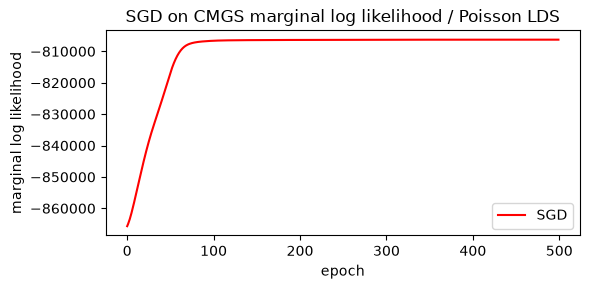

In [17]:
%matplotlib inline 
# Plot loss curve
plt.figure(figsize=(6, 3))
plt.plot(-jnp.array(losses), color="r", label="SGD")
plt.xlabel("epoch"); plt.ylabel("marginal log likelihood")
plt.title("SGD on CMGS marginal log likelihood / Poisson LDS")
plt.legend(); plt.tight_layout()

# Rotating latents to match ground truth

In [18]:
from wasabi.plds_fit import alignment

# Align fitted latents into the ground-truth latent basis: x ≈ W z
C_true = np.asarray(params_GT["C"])
_, W_fit = alignment(C_fit, C_true)
_, W_init = alignment(C_init, C_true)

X_hat = np.asarray(posts_fit.smoothed_means) @ W_fit.T
X_hat_init = np.asarray(posts_init.smoothed_means) @ W_init.T

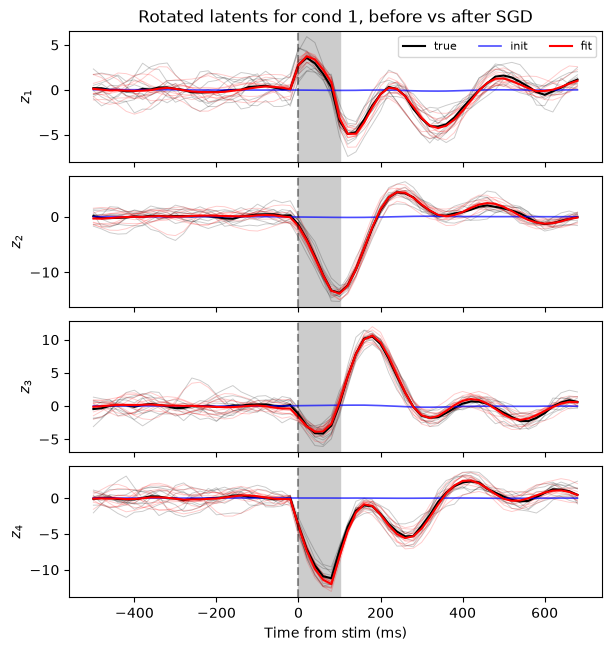

In [19]:
condition = 0
sel = cond_id == condition

fig, axs = plt.subplots(K, 1, figsize=(6, 1.6 * K), constrained_layout=True, sharex=True)

for d in range(K):
    for trace in X[sel][:, :, d]:
        axs[d].plot(t_ms, trace, color="k", alpha=0.2, linewidth=0.7)
    for trace in X_hat[sel][:, :, d]:
        axs[d].plot(t_ms, trace, color="r", alpha=0.2, linewidth=0.7)

    axs[d].axvspan(*blank_ms, color="0.8", zorder=0)
    axs[d].plot(t_ms, X[sel][:, :, d].mean(axis=0), color="k", linewidth=1.5, label="true")
    axs[d].plot(t_ms, X_hat_init[sel][:, :, d].mean(axis=0), color="b", linewidth=1.2, alpha=0.7, label="init")
    axs[d].plot(t_ms, X_hat[sel][:, :, d].mean(axis=0), color="r", linewidth=1.5, label="fit")
    axs[d].axvline(stim_t_ms, color="k", linestyle="--", alpha=0.4)
    axs[d].set_ylabel(rf"$z_{{{d+1}}}$")

axs[0].set_title(f"Rotated latents for cond {condition+1}, before vs after SGD")
axs[0].legend(fontsize=8, ncol=3)
axs[-1].set_xlabel("Time from stim (ms)")
plt.show()

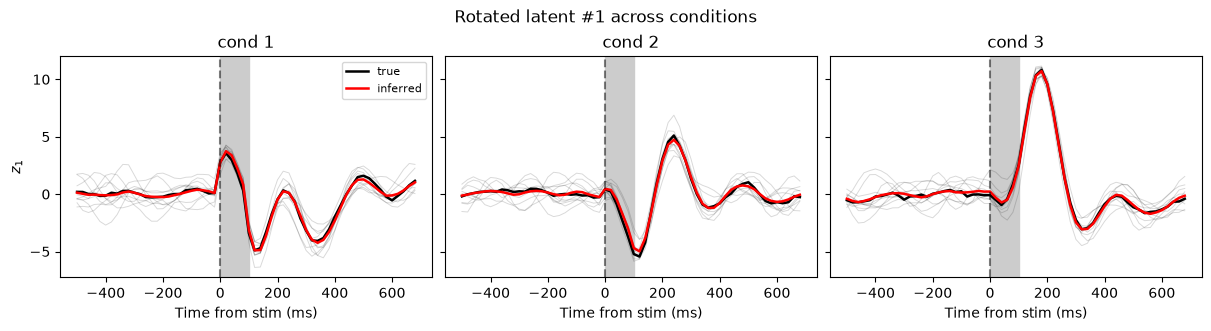

In [20]:
latent = 0
n_show = 3

fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 3.2), constrained_layout=True, sharey=True)

for ax, condition in zip(axes, range(n_show)):
    sel = cond_id == condition
    for trace in X_hat[sel][:, :, latent]:
        ax.plot(t_ms, trace, color="k", alpha=0.15, linewidth=0.7)
    ax.plot(t_ms, X[sel][:, :, latent].mean(axis=0), color="k", linewidth=1.8, label="true")
    ax.plot(t_ms, X_hat[sel][:, :, latent].mean(axis=0), color="r", linewidth=1.8, label="inferred")
    ax.axvspan(*blank_ms, color="0.8", zorder=0)
    ax.axvline(stim_t_ms, color="k", linestyle="--", alpha=0.5)
    ax.set_title(f"cond {condition+1}")
    ax.set_xlabel("Time from stim (ms)")

axes[0].set_ylabel(rf"$z_{{{latent+1}}}$")
axes[0].legend(fontsize=8)
fig.suptitle("Rotated latent #1 across conditions")
plt.show()

# Reconstructed firing rates

In [21]:
from wasabi.utils import softplus_np

lam_hat = np.asarray(predicted_rates)  # (n_trials, T, N)

# Ground truth rates from the true latents
lam_true = softplus_np(X @ params_GT["C"].T + params_GT["d"], BETA_EMIT)

# Baseline: per-channel mean rate, what a model with no latents would say
lam_base = np.broadcast_to(lam_true.mean(axis=(0, 1)), lam_true.shape)

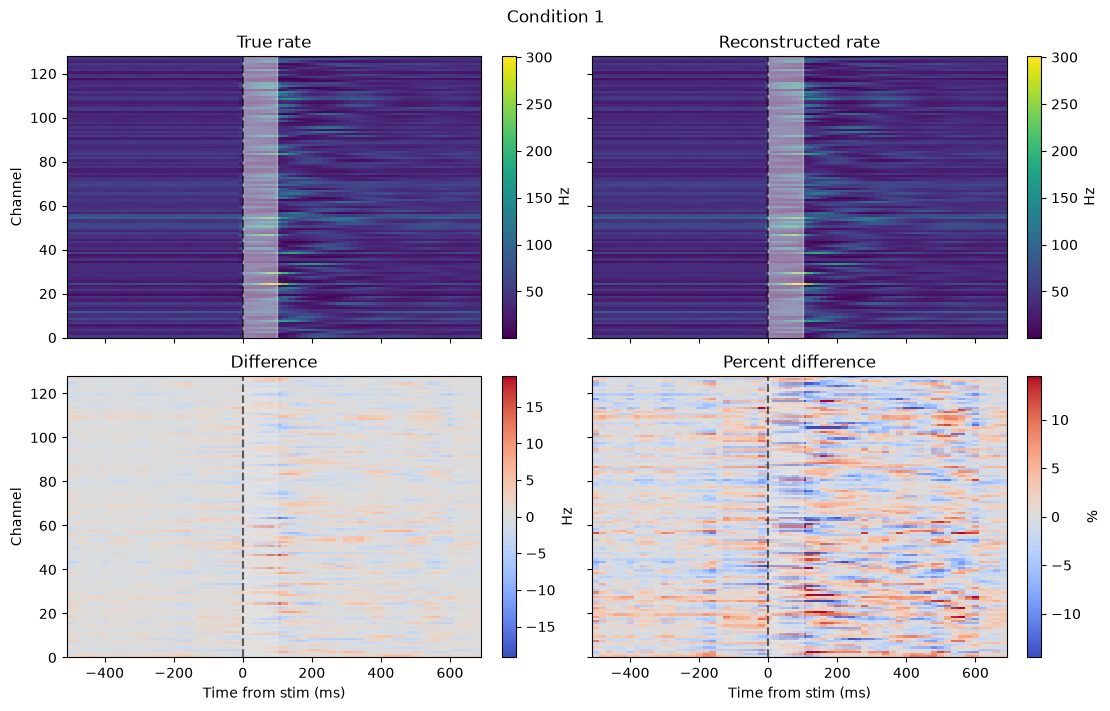

In [22]:
condition = 0
sel = cond_id == condition

hz = 1000.0 / BIN_SIZE  # counts per bin -> Hz

lam_true_c = lam_true[sel].mean(axis=0).T * hz  # (N, T)
lam_hat_c = lam_hat[sel].mean(axis=0).T * hz
diff_c = lam_hat_c - lam_true_c
pct_c = 100.0 * diff_c / np.maximum(lam_true_c, 1e-9)  # guard near-silent channels

vmin = min(lam_true_c.min(), lam_hat_c.min())
vmax = max(lam_true_c.max(), lam_hat_c.max())
dlim = np.abs(diff_c).max()
plim = np.percentile(np.abs(pct_c), 99)  # clip the tail so the map stays readable

edges_ms = t_edges_ms
y_edges = np.arange(lam_true_c.shape[0] + 1)

panels = [
    (lam_true_c, "True rate", "viridis", vmin, vmax, "Hz"),
    (lam_hat_c, "Reconstructed rate", "viridis", vmin, vmax, "Hz"),
    (diff_c, "Difference", "coolwarm", -dlim, dlim, "Hz"),
    (pct_c, "Percent difference", "coolwarm", -plim, plim, "%"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True, sharex=True, sharey=True)

for i, (ax, (data, title, cmap, lo, hi, cbar_label)) in enumerate(zip(axes.ravel(), panels)):
    pc = ax.pcolormesh(edges_ms, y_edges, data, shading="flat", cmap=cmap, vmin=lo, vmax=hi)
    ax.invert_yaxis()
    ax.axvline(stim_t_ms, linestyle="--", color="k", alpha=0.6)
    ax.axvspan(*blank_ms, color="0.9", alpha=0.5, zorder=1)
    ax.set_title(title)
    if i // 2 == 1:
        ax.set_xlabel("Time from stim (ms)")
    if i % 2 == 0:
        ax.set_ylabel("Channel")
    fig.colorbar(pc, ax=ax, label=cbar_label)

fig.suptitle(f"Condition {condition+1}")
plt.show()

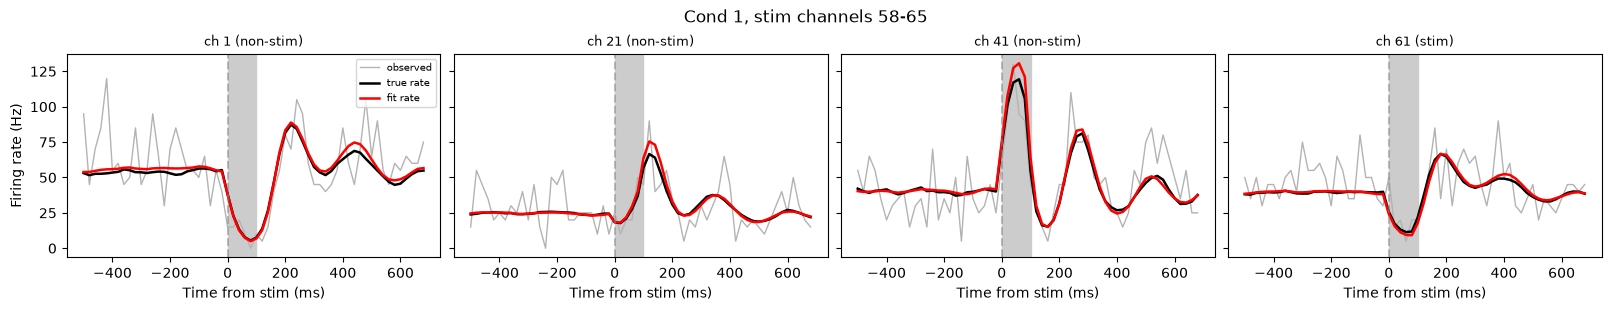

In [23]:
# Plot example channel / mean observed spike counts and FR
condition = 0
sel = cond_id == condition
chans = [0, 20, 40, 60]

hz = 1000.0 / BIN_SIZE
stim_idx = np.flatnonzero(S[sel][0, t_stim] > 0)
stim_lo, stim_hi = stim_idx.min() + 1, stim_idx.max() + 1

fig, axes = plt.subplots(1, len(chans), figsize=(4 * len(chans), 3), constrained_layout=True, sharex=True, sharey=True)

for ax, ch in zip(axes, chans):
    ax.plot(t_ms, Y[sel][:, :, ch].mean(axis=0) * hz, color="0.7", lw=1, label="observed")
    ax.plot(t_ms, lam_true[sel][:, :, ch].mean(axis=0) * hz, "k", lw=1.8, label="true rate")
    ax.plot(t_ms, lam_hat[sel][:, :, ch].mean(axis=0) * hz, "r", lw=1.8, label="fit rate")
    ax.axvspan(*blank_ms, color="0.8", zorder=0)
    ax.axvline(stim_t_ms, color="grey", ls="--", alpha=0.5)
    tag = "stim" if ch in stim_idx else "non-stim"
    ax.set_title(f"ch {ch+1} ({tag})", fontsize=9)
    ax.set_xlabel("Time from stim (ms)")

axes[0].set_ylabel("Firing rate (Hz)")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle(f"Cond {condition+1}, stim channels {stim_lo}-{stim_hi}")
plt.show()

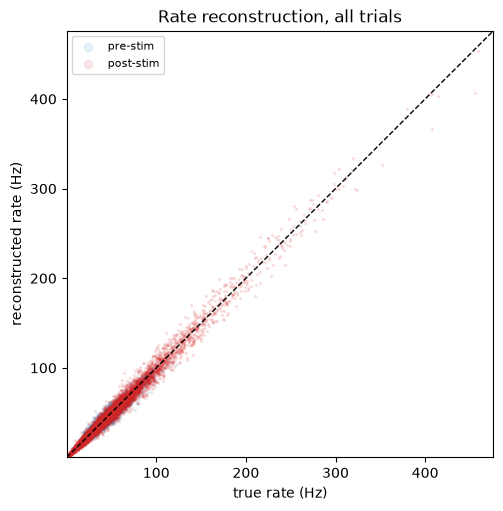

In [24]:
rng_plot = np.random.default_rng(0)
idx = rng_plot.choice(lam_true.size, size=20000, replace=False)

hz = 1000.0 / BIN_SIZE

lt = lam_true.ravel()[idx] * hz
lh = lam_hat.ravel()[idx] * hz

pre_mask = np.zeros_like(lam_true, dtype=bool)
pre_mask[:, :t_stim, :] = True
is_pre = pre_mask.ravel()[idx]

fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
ax.scatter(lt[is_pre], lh[is_pre], s=2, alpha=0.1, color="tab:blue", label="pre-stim")
ax.scatter(lt[~is_pre], lh[~is_pre], s=2, alpha=0.1, color="tab:red", label="post-stim")

lo = min(lt.min(), lh.min())
hi = max(lt.max(), lh.max())
ax.plot([lo, hi], [lo, hi], "k--", lw=1)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_xlabel("true rate (Hz)")
ax.set_ylabel("reconstructed rate (Hz)")
ax.set_title("Rate reconstruction, all trials")
ax.legend(fontsize=8, markerscale=4)
plt.show()

In [25]:
def rate_metrics(lam_true, lam_hat, label=""):
    err = lam_hat - lam_true # trials x time x channels
    rmse = np.sqrt(np.mean(err ** 2)) # Across all trials, time and channels
    rel_frob = np.linalg.norm(err) / np.linalg.norm(lam_true) # Norm relative to true norm

    # Per channel
    # Coefficient of determination
    ss_res = np.sum(err ** 2, axis=(0, 1)) # residual per channel
    ss_tot = np.sum((lam_true - lam_true.mean(axis=(0, 1))) ** 2, axis=(0, 1)) # Total error per channel relative to channel mean
    r2_ch = 1.0 - ss_res / ss_tot # Per channel R^2
    r2_pop = 1.0 - ss_res.sum() / ss_tot.sum() # R^2 across all channels

    # Pearson correlation
    lt = lam_true.reshape(-1, lam_true.shape[-1]) #
    lh = lam_hat.reshape(-1, lam_hat.shape[-1])
    lt_c, lh_c = lt - lt.mean(0), lh - lh.mean(0)
    corr_ch = (lt_c * lh_c).sum(0) / (np.linalg.norm(lt_c, axis=0) * np.linalg.norm(lh_c, axis=0) + 1e-12) # Per channel Pearson correlation

    print(f"{label}")
    print(f"  RMSE (rates)        : {rmse:.4f}")
    print(f"  relative Frobenius  : {rel_frob:.4f}")
    print(f"  population R^2      : {r2_pop:.4f}")
    print(f"  median channel R^2  : {np.median(r2_ch):.4f}")
    print(f"  median channel corr : {np.median(corr_ch):.4f}")
    return dict(rmse=rmse, r2_pop=r2_pop, r2_ch=r2_ch, corr_ch=corr_ch)

x_fit   = rate_metrics(lam_true[:, ~blank], lam_hat[:, ~blank], "fitted (observed)")
x_blank = rate_metrics(lam_true[:, blank],  lam_hat[:, blank],  "fitted (interpolated)")

fitted (observed)
  RMSE (rates)        : 0.0758
  relative Frobenius  : 0.0755
  population R^2      : 0.9722
  median channel R^2  : 0.9667
  median channel corr : 0.9847
fitted (interpolated)
  RMSE (rates)        : 0.1316
  relative Frobenius  : 0.0779
  population R^2      : 0.9858
  median channel R^2  : 0.9812
  median channel corr : 0.9928


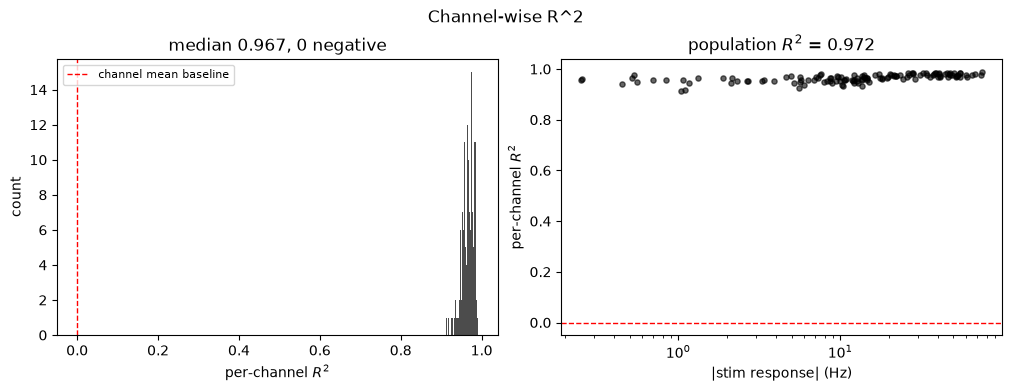

In [26]:
hz = 1000.0 / BIN_SIZE
r2 = x_fit["r2_ch"]
resp = (lam_true[:, t_stim:t_stim + 10, :].mean(axis=(0, 1))
        - lam_true[:, :t_stim, :].mean(axis=(0, 1))) * hz

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)

ax = axes[0]
ax.hist(r2, bins=30, color="k", alpha=0.7)
ax.axvline(0, color="r", ls="--", lw=1, label="channel mean baseline")
ax.set_xlabel("per-channel $R^2$")
ax.set_ylabel("count")
ax.set_title(f"median {np.median(r2):.3f}, {np.sum(r2 < 0)} negative")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
ax.scatter(np.abs(resp), r2, s=14, color="k", alpha=0.6)
ax.axhline(0, color="r", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("|stim response| (Hz)")
ax.set_ylabel("per-channel $R^2$")
ax.set_title(f"population $R^2$ = {x_fit['r2_pop']:.3f}")

fig.suptitle("Channel-wise R^2")
plt.show()

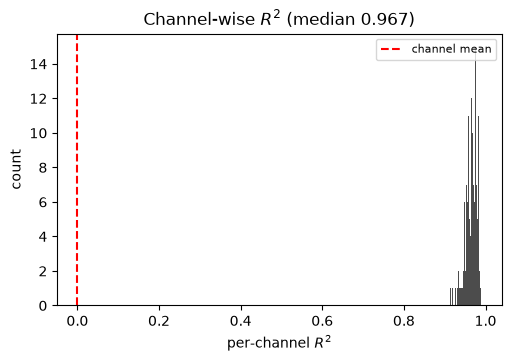

In [27]:
fig, ax = plt.subplots(figsize=(5, 3.5), constrained_layout=True)

ax.hist(x_fit["r2_ch"], bins=30, color="k", alpha=0.7)
ax.axvline(0, color="r", ls="--", label="channel mean")
ax.set_xlabel("per-channel $R^2$")
ax.set_ylabel("count")
ax.set_title(f"Channel-wise $R^2$ (median {np.median(x_fit['r2_ch']):.3f})")
ax.legend(fontsize=8, loc='upper right')

plt.show()

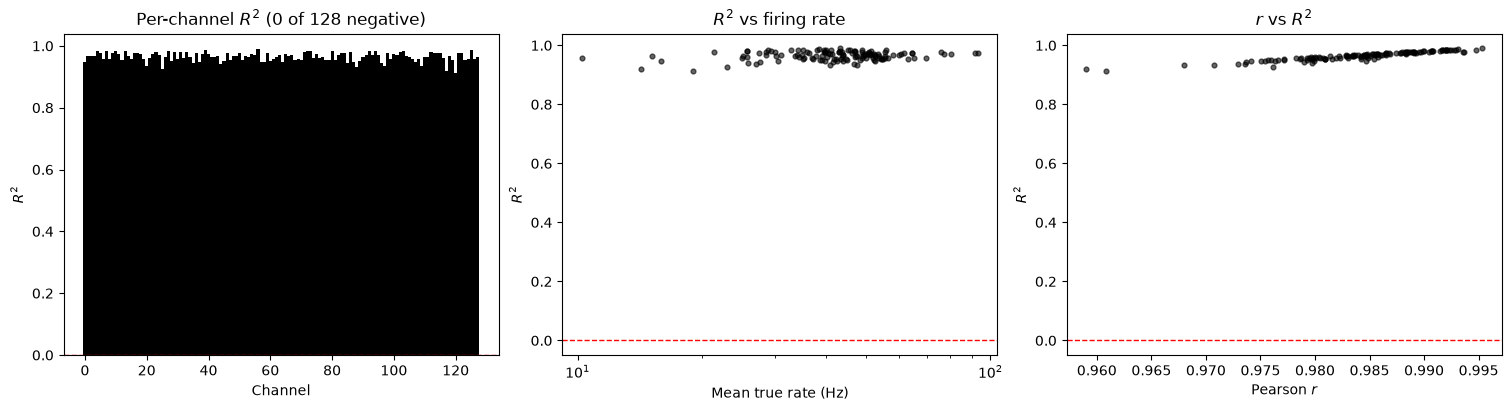

negative-R2 channels: []
  median mean rate : nan Hz (vs 43.54 Hz for the rest)
  median Pearson r : nan


/home/bryan/Documents/workspace/WASABI/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/bryan/Documents/workspace/WASABI/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [28]:
hz = 1000.0 / BIN_SIZE
r2 = x_fit["r2_ch"]
corr = x_fit["corr_ch"]
mean_rate = lam_true.mean(axis=(0, 1)) * hz  # per-channel mean rate, Hz
chans = np.arange(len(r2))
bad = r2 < 0

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

# R^2 by channel index
ax = axes[0]
ax.bar(chans[~bad], r2[~bad], color="k", width=1.0)
ax.bar(chans[bad], r2[bad], color="tab:red", width=1.0)
ax.axhline(0, color="r", ls="--", lw=1)
ax.set_xlabel("Channel")
ax.set_ylabel("$R^2$")
ax.set_title(f"Per-channel $R^2$ ({bad.sum()} of {len(r2)} negative)")

# R^2 vs mean firing rate: is it the quiet channels?
ax = axes[1]
ax.scatter(mean_rate[~bad], r2[~bad], s=12, color="k", alpha=0.6)
ax.scatter(mean_rate[bad], r2[bad], s=12, color="tab:red", alpha=0.6)
ax.axhline(0, color="r", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Mean true rate (Hz)")
ax.set_ylabel("$R^2$")
ax.set_title("$R^2$ vs firing rate")

# R^2 vs Pearson: offset problem or shape problem?
ax = axes[2]
ax.scatter(corr[~bad], r2[~bad], s=12, color="k", alpha=0.6)
ax.scatter(corr[bad], r2[bad], s=12, color="tab:red", alpha=0.6)
ax.axhline(0, color="r", ls="--", lw=1)
ax.set_xlabel("Pearson $r$")
ax.set_ylabel("$R^2$")
ax.set_title("$r$ vs $R^2$")

# fig.suptitle("Where the negative $R^2$ channels are")
plt.show()

print(f"negative-R2 channels: {chans[bad].tolist()}")
print(f"  median mean rate : {np.median(mean_rate[bad]):.2f} Hz "
      f"(vs {np.median(mean_rate[~bad]):.2f} Hz for the rest)")
print(f"  median Pearson r : {np.median(corr[bad]):.3f}")

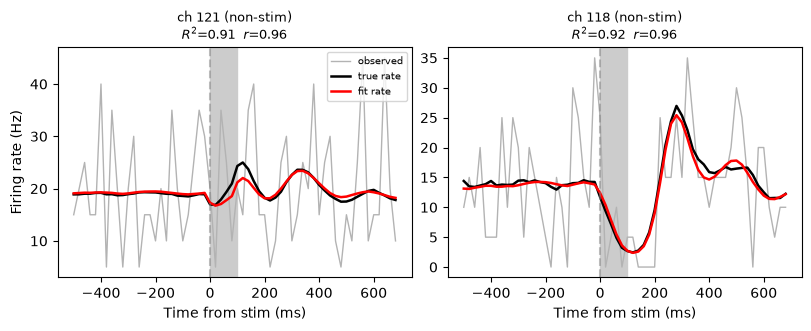

In [29]:
condition = 0
sel = cond_id == condition
n_show = 2

hz = 1000.0 / BIN_SIZE
r2 = x_fit["r2_ch"]
bad_chans = np.argsort(r2)[:n_show]

stim_idx = np.flatnonzero(S[sel][0, t_stim] > 0)
stim_lo, stim_hi = stim_idx.min() + 1, stim_idx.max() + 1

fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 3.2), constrained_layout=True, sharex=True)

for ax, ch in zip(axes, bad_chans):
    ax.plot(t_ms, Y[sel][:, :, ch].mean(axis=0) * hz, color="0.7", lw=1, label="observed")
    ax.plot(t_ms, lam_true[sel][:, :, ch].mean(axis=0) * hz, "k", lw=1.8, label="true rate")
    ax.plot(t_ms, lam_hat[sel][:, :, ch].mean(axis=0) * hz, "r", lw=1.8, label="fit rate")
    ax.axvspan(*blank_ms, color="0.8", zorder=0)
    ax.axvline(stim_t_ms, color="grey", ls="--", alpha=0.5)
    tag = "stim" if ch in stim_idx else "non-stim"
    ax.set_title(f"ch {ch+1} ({tag})\n$R^2$={r2[ch]:.2f}  $r$={x_fit['corr_ch'][ch]:.2f}", fontsize=9)
    ax.set_xlabel("Time from stim (ms)")

axes[0].set_ylabel("Firing rate (Hz)")
axes[0].legend(fontsize=7, loc="upper right")
plt.show()

In [30]:
# Ground truth
A_true = np.asarray(params_GT["A"])
C_true = np.asarray(params_GT["C"])
d_true = np.asarray(params_GT["d"])
B_true = np.asarray(params_GT["B"])
b_true = np.asarray(params_GT["b"])

# Recovered Params
A_est = np.asarray(A_fit)
C_est = np.asarray(C_fit)
d_est = np.asarray(d_fit)
B_est = np.asarray(B_SCALE * B_fit)
b_est = np.asarray(b_fit)

# Complete list of pairs to visualize
pairs = [
    ("A", A_true, A_est),
    ("C", C_true, C_est),
    ("d", d_true, d_est),
    ("B", B_true, B_est),
    ("b", b_true, b_est)
]

--- Aligned Vector/Scalar Norms ---
d: GT Norm: 6.0091, Fitted Norm: 6.0231, Diff Norm: 0.2717
b: GT Norm: 0.5000, Fitted Norm: 0.0986, Diff Norm: 0.5986


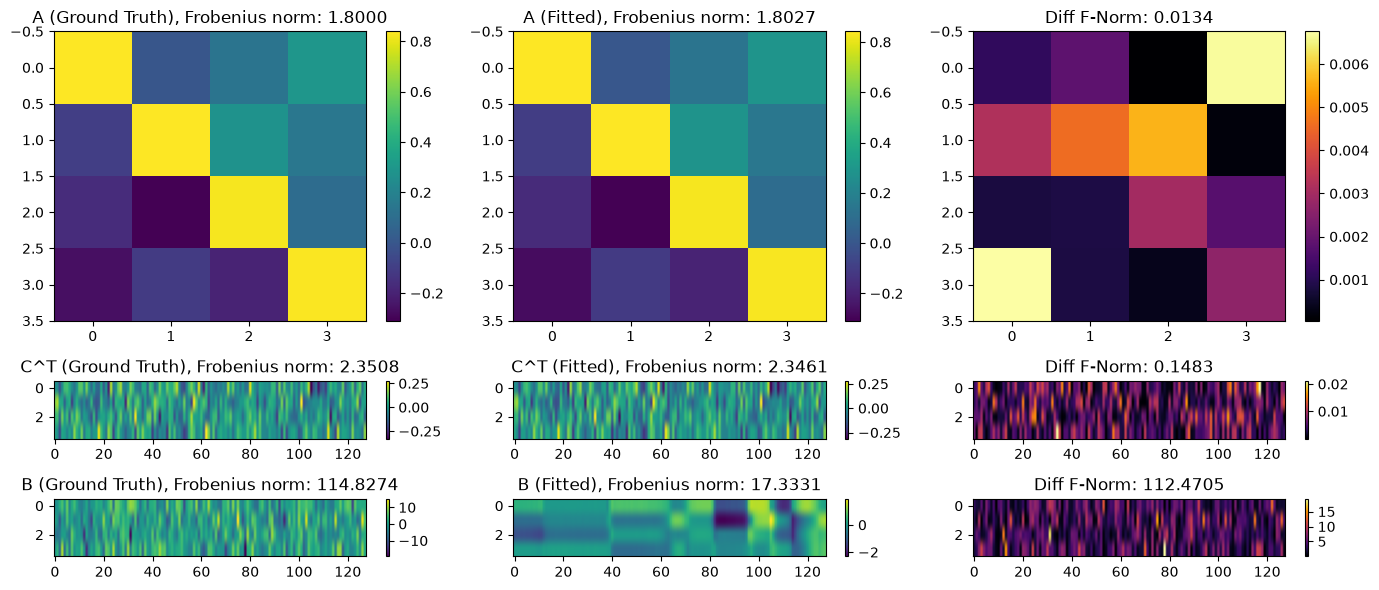

In [31]:
from wasabi.plds_fit import alignment

# 1. Compute the alignment matrix M using the observation matrices C
# We want C_est @ M_inv ≈ C_true -> M_inv = pinv(C_est) @ C_true
C_true_raw = np.asarray(params_GT["C"])
C_est_raw = np.asarray(C_fit)

rot, rot_inv = alignment(C_true_raw, C_est_raw)

# 2. Align the recovered parameters back to ground-truth space
A_aligned = rot @ A_est @ rot_inv
B_aligned = rot @ B_est
C_aligned = C_est_raw @ rot_inv

# Keep d and b as they are not affected by latent rotation
d_aligned = d_est
b_aligned = b_est

# --- Print Statements for Scalars/Vectors ---
print("--- Aligned Vector/Scalar Norms ---")
for name, true_val, est_val in [("d", d_true, d_aligned), ("b", b_true, b_aligned)]:
    t_arr = np.asarray(true_val)
    e_arr = np.asarray(est_val)
    true_norm = np.linalg.norm(t_arr)
    est_norm = np.linalg.norm(e_arr)
    diff_norm = np.linalg.norm(t_arr - e_arr)
    print(f"{name}: GT Norm: {true_norm:.4f}, Fitted Norm: {est_norm:.4f}, Diff Norm: {diff_norm:.4f}")

# --- Plotting the Aligned Matrices ---
pairs = [
    ("A", A_true, A_aligned),
    ("C", C_true_raw, C_aligned),
    ("B", B_true, B_aligned)
]

num_rows = len(pairs)
row_heights = [1.0, 0.2, 0.2]

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(num_rows, 3, height_ratios=row_heights)

for i, (name, true, est) in enumerate(pairs):
    true = np.asarray(true)
    est = np.asarray(est)
    
    if name == "C":
        true = true.T
        est = est.T
        display_name = "C^T"
    else:
        display_name = name

    true_norm = np.linalg.norm(true)
    est_norm = np.linalg.norm(est)
    frob_norm = np.linalg.norm(true - est)
    
    error_matrix = np.abs(true - est)

    # Column 1: Ground Truth
    ax1 = fig.add_subplot(gs[i, 0])
    im1 = ax1.imshow(true, aspect='auto', cmap='viridis')
    fig.colorbar(im1, ax=ax1, pad=0.05)
    ax1.set_title(f"{display_name} (Ground Truth), Frobenius norm: {true_norm:.4f}")
    
    # Column 2: Estimate
    ax2 = fig.add_subplot(gs[i, 1])
    im2 = ax2.imshow(est, aspect='auto', cmap='viridis')
    fig.colorbar(im2, ax=ax2, pad=0.05)
    ax2.set_title(f"{display_name} (Fitted), Frobenius norm: {est_norm:.4f}")
    
    # Column 3: Absolute Error
    ax3 = fig.add_subplot(gs[i, 2])
    im3 = ax3.imshow(error_matrix, aspect='auto', cmap='inferno')
    fig.colorbar(im3, ax=ax3, pad=0.05)
    ax3.set_title(f"Diff F-Norm: {frob_norm:.4f}")

plt.tight_layout()
plt.show()